# Lab 3 – Part B: Insurance Cost Prediction (Linear Regression)

**Name:** Sultan Akinola Atanda | **Student ID:** 9114837

1,338 insurance holders with age, sex, BMI, children, smoker and region, and the target `charges` (yearly medical cost). The goal is to build a linear regression model that predicts insurance cost, using a 70/30 train/test split.

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

pio.renderers.default = "plotly_mimetype+notebook_connected"
pio.templates.default = "plotly_white"
SMOKER, NONSMOKER = "#f4a261", "#2a9d8f"
HIGHLIGHT = "#e63946"
RANDOM_STATE = 42

## B1. Load and check the data

In [2]:
ins = pd.read_csv("insurance.csv")
print("Shape:", ins.shape)
print("Missing values:", ins.isna().sum().sum())
print("Duplicate rows:", ins.duplicated().sum())
ins = ins.drop_duplicates().reset_index(drop=True)
ins.describe().round(2)

Shape: (1338, 7)
Missing values: 0
Duplicate rows: 1


,age,bmi,children,charges
count,1337.00,1337.00,1337.00,1337.00
mean,39.22,30.66,1.10,13279.12
std,14.04,6.10,1.21,12110.36
min,18.00,15.96,0.00,1121.87
25%,27.00,26.29,0.00,4746.34
50%,39.00,30.40,1.00,9386.16
75%,51.00,34.70,2.00,16657.72
max,64.00,53.13,5.00,63770.43


No missing values and one duplicate row, which was dropped (1,337 rows left). Charges range from ~1,100 to ~63,800, and the mean (13,279) is well above the median (9,386), so the target is right-skewed.

## B2. Exploratory analysis

smoker
no      8441.0
yes    32050.0
Name: charges, dtype: float64


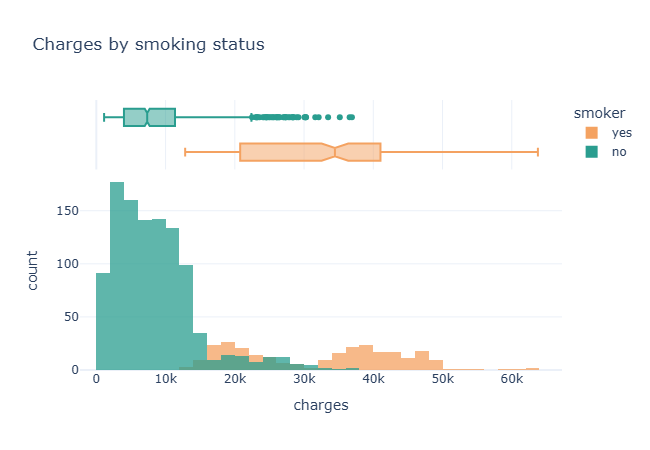

In [3]:
print(ins.groupby("smoker")["charges"].mean().round(0))
fig = px.histogram(ins, x="charges", color="smoker", nbins=60, barmode="overlay", opacity=0.75, marginal="box",
                   color_discrete_map={"yes": SMOKER, "no": NONSMOKER}, title="Charges by smoking status")
fig.update_layout(height=450)
fig.show()

Smoking explains most of the skew: **smokers pay almost 4x more** on average (32,050 vs 8,441). Non-smokers cluster at the low end while smokers spread up to 60k+.

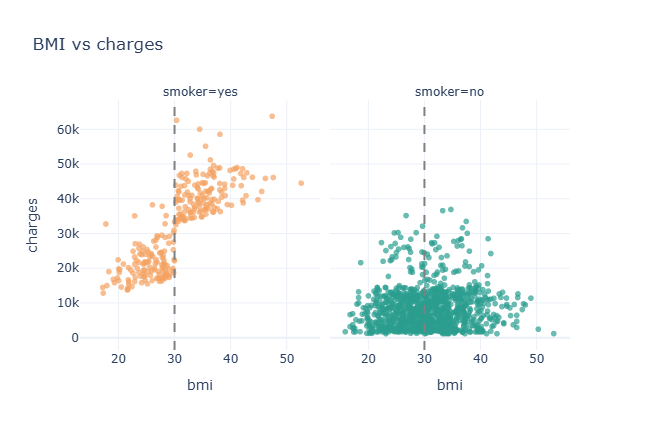

In [4]:
fig = px.scatter(ins, x="bmi", y="charges", color="smoker", facet_col="smoker", opacity=0.7,
                 color_discrete_map={"yes": SMOKER, "no": NONSMOKER}, title="BMI vs charges")
fig.add_vline(x=30, line_dash="dash", line_color="grey")
fig.update_layout(height=430, showlegend=False)
fig.show()

BMI barely affects non-smokers, but for smokers there is a sharp **jump at BMI 30** (obese): obese smokers pay roughly 20k more. A plain linear model can't capture this on its own, so I revisit it in B5.

## B3. Encoding and 70/30 split

Categorical columns are one-hot encoded with `drop_first=True` to avoid the dummy variable trap.

In [5]:
ins_enc = pd.get_dummies(ins, columns=["sex", "smoker", "region"], drop_first=True, dtype=int)
print(ins_enc.corr()["charges"].drop("charges").sort_values(ascending=False).round(3))

X = ins_enc.drop(columns="charges")
y = ins_enc["charges"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)
print("\nTrain:", X_train.shape, "| Test:", X_test.shape)

smoker_yes          0.787
age                 0.298
bmi                 0.198
region_southeast    0.074
children            0.067
sex_male            0.058
region_northwest   -0.039
region_southwest   -0.044
Name: charges, dtype: float64

Train: (935, 8) | Test: (402, 8)


`smoker_yes` has the strongest correlation with charges (0.79), then `age` (0.30) and `bmi` (0.20). The split gives 935 training and 402 test rows.

## B4. Train and evaluate the model

In [6]:
lin_reg = LinearRegression().fit(X_train, y_train)
y_pred = lin_reg.predict(X_test)

print(f"R² train: {lin_reg.score(X_train, y_train):.4f}")
print(f"R² test:  {r2_score(y_test, y_pred):.4f}")
print(f"MAE:  {mean_absolute_error(y_test, y_pred):,.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):,.2f}\n")
print(pd.Series(lin_reg.coef_, index=X.columns).round(2).sort_values(ascending=False))

R² train: 0.7363
R² test:  0.7724
MAE:  4,181.82
RMSE: 6,240.21

smoker_yes          22874.45
children              522.16
bmi                   328.38
age                   251.25
sex_male             -111.91
region_northwest     -465.75
region_southwest     -765.58
region_southeast     -936.10
dtype: float64


The model explains **77.2%** of the variance in charges on the test set, with an average error (MAE) of about **4,182**. Train R² (0.736) is close, so no overfitting.

The coefficients show that being a **smoker adds ~22,874** per year; each year of age adds ~251, each BMI point ~328 and each child ~522. Sex and region only shift the cost by a few hundred.

## B5. Improving the model with feature engineering

Based on the EDA, I add `obese` (BMI ≥ 30), `smoker_obese` (smoker and obese) and `age_sq` (age squared). It's still linear regression, just with better features.

In [7]:
ins_fe = ins_enc.copy()
ins_fe["obese"] = (ins_fe["bmi"] >= 30).astype(int)
ins_fe["smoker_obese"] = ins_fe["smoker_yes"] * ins_fe["obese"]
ins_fe["age_sq"] = ins_fe["age"] ** 2

X_fe = ins_fe.drop(columns="charges")
X_train_fe, X_test_fe, y_train, y_test = train_test_split(X_fe, y, test_size=0.3, random_state=RANDOM_STATE)
lin_reg_fe = LinearRegression().fit(X_train_fe, y_train)
y_pred_fe = lin_reg_fe.predict(X_test_fe)

pd.DataFrame({
    "R² test": [r2_score(y_test, p) for p in (y_pred, y_pred_fe)],
    "MAE": [mean_absolute_error(y_test, p) for p in (y_pred, y_pred_fe)],
    "RMSE": [np.sqrt(mean_squared_error(y_test, p)) for p in (y_pred, y_pred_fe)],
}, index=["Baseline", "Engineered"]).round(4)

,R² test,MAE,RMSE
Baseline,0.7724,4181.8160,6240.2059
Engineered,0.8750,2515.2677,4624.0056


Test R² improves from **0.772 to 0.875** and MAE drops from ~ 4,182 to **~2,515**, about 40% smaller errors.

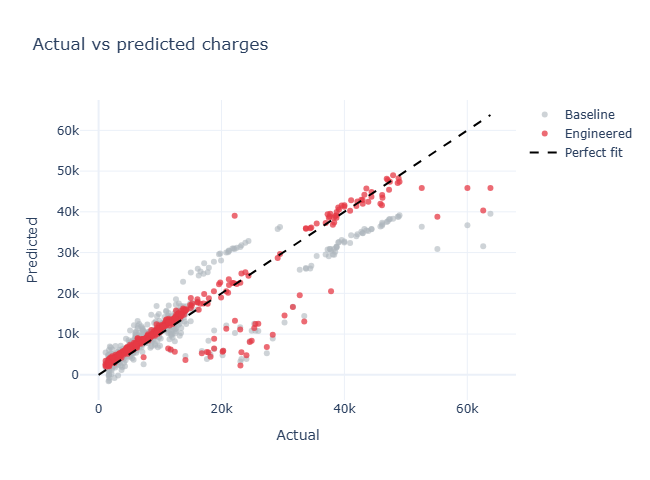

In [8]:
lim = [0, max(y_test.max(), y_pred_fe.max())]
fig = go.Figure()
fig.add_trace(go.Scatter(x=y_test, y=y_pred, mode="markers", name="Baseline", marker=dict(color="#adb5bd", opacity=0.6)))
fig.add_trace(go.Scatter(x=y_test, y=y_pred_fe, mode="markers", name="Engineered", marker=dict(color=HIGHLIGHT, opacity=0.75)))
fig.add_trace(go.Scatter(x=lim, y=lim, mode="lines", name="Perfect fit", line=dict(color="black", dash="dash")))
fig.update_layout(title="Actual vs predicted charges", xaxis_title="Actual", yaxis_title="Predicted", height=480)
fig.show()

The engineered model's points sit much closer to the diagonal, especially for high-cost smokers. A few points stay well above the line; these are unusually high costs the available features can't explain.

## B6. Predicting for new customers

In [9]:
new = pd.DataFrame([
    {"age": 30, "sex": "male", "bmi": 32.0, "children": 1, "smoker": "yes", "region": "northeast"},
    {"age": 30, "sex": "male", "bmi": 32.0, "children": 1, "smoker": "no", "region": "northeast"},
])
new_enc = pd.get_dummies(new, columns=["sex", "smoker", "region"], dtype=int).reindex(columns=X.columns, fill_value=0)
new_enc["obese"] = (new_enc["bmi"] >= 30).astype(int)
new_enc["smoker_obese"] = new_enc["smoker_yes"] * new_enc["obese"]
new_enc["age_sq"] = new_enc["age"] ** 2

new["predicted_charges"] = lin_reg_fe.predict(new_enc[X_fe.columns]).round(2)
new

,age,sex,bmi,children,smoker,region,predicted_charges
0,30,male,32.0,1,yes,northeast,38272.01
1,30,male,32.0,1,no,northeast,5430.71


Two identical customers, except one smokes: the smoker is predicted at about **38,272** a year versus **5,431** for the non-smoker, roughly 7x more.

## Conclusion
- One duplicate removed; categorical features one-hot encoded.
- **Smoking** is the biggest cost driver, followed by age and BMI, with BMI mattering mainly for smokers.
- Baseline linear regression: **R² = 0.772**, MAE ≈ 4,182.
- With `obese`, `smoker_obese` and `age_sq`: **R² = 0.875**, MAE ≈ 2,515.